# El Juego de los Números Uniformes
**Taller de Resolución de Problemas III — Universidad Austral — 2026**

Integrantes: (completar)

## Método de resolución

Resolvemos el problema de forma **analítica** y verificamos cada resultado con **simulación (Monte Carlo)**.

Lo hacemos en dos etapas:

1. **Etapa 1:** el Jugador 1 frente a un rival con un número uniforme (0,1), eligiendo para cada número la opción con mayor probabilidad de ganar.
2. **Etapa 2:** el juego completo, donde el Jugador 2 conoce la opción elegida por el Jugador 1 (pero no su número) y decide en consecuencia.

## Etapa 1: rival uniforme (0,1)

### Hipótesis

1. El número final del rival es **uniforme en (0,1)**: el rival no elige ninguna opción, tiene un número al azar.
2. El Jugador 1 elige, para cada número que le toca, la opción con **mayor probabilidad de ganar**.
3. Los números son independientes entre sí.
4. La probabilidad de empate es 0 (dos números uniformes casi nunca son iguales).

### Resolución

Nos toca un número $x$ y comparamos la probabilidad de ganar de cada opción:

- **Plantarse:** termino con $x$. Gano si el rival tiene menos que $x$ → $P = x$
- **Complementar:** termino con $1-x$. Gano si el rival tiene menos que $1-x$ → $P = 1-x$
- **Sortear de nuevo:** los dos tenemos un número al azar con la misma distribución; por simetría cada uno gana la mitad de las veces → $P = 0.5$

**Ejemplos:**

- $x = 0.9$: plantarse 0.9, complementar 0.1, sortear 0.5 → **me planto**
- $x = 0.2$: plantarse 0.2, complementar 0.8, sortear 0.5 → **complemento**
- $x = 0.45$: plantarse 0.45, complementar 0.55, sortear 0.5 → **complemento** (por poco)

Entre $x$ y $1-x$, siempre uno de los dos es al menos 0.5. Entonces **sortear nunca conviene**.

**Estrategia:** me planto si $x \geq 0.5$ y complemento si $x < 0.5$. Siempre termino con $\max(x, 1-x)$.

In [19]:
import numpy as np

# Semilla para reproducir los resultados
np.random.seed(2026)

def mejor_opcion(x):
    p_plantarse = x
    p_complementar = 1 - x
    p_sortear = 0.5

    if p_plantarse >= p_complementar and p_plantarse >= p_sortear:
        return "plantarse", p_plantarse
    elif p_complementar >= p_sortear:
        return "complementar", p_complementar
    else:
        return "sortear", p_sortear

In [20]:
for x in [0.9, 0.2, 0.45, 0.5, 0.6]:
    opcion, prob = mejor_opcion(x)
    print("x =", x, "→", opcion, "con P(ganar) =", round(prob, 2))

x = 0.9 → plantarse con P(ganar) = 0.9
x = 0.2 → complementar con P(ganar) = 0.8
x = 0.45 → complementar con P(ganar) = 0.55
x = 0.5 → plantarse con P(ganar) = 0.5
x = 0.6 → plantarse con P(ganar) = 0.6


### Verificación por simulación

Para un número fijo $x$, jugamos muchas veces contra un rival uniforme (0,1) y contamos cuántas veces gana cada opción. Si las cuentas están bien, tiene que dar cerca de $x$, $1-x$ y $0.5$.

In [21]:
def simular_opciones(x, n):
    rival = np.random.rand(n)            # números del rival, uniformes (0,1)
    nuevo = np.random.rand(n)            # número nuevo si sorteo

    gana_plantarse = np.mean(x > rival)
    gana_complementar = np.mean(1 - x > rival)
    gana_sortear = np.mean(nuevo > rival)

    return gana_plantarse, gana_complementar, gana_sortear

for x in [0.9, 0.2, 0.45]:
    p1, p2, p3 = simular_opciones(x, 100000)
    print("x =", x, "| plantarse:", round(p1, 3), "| complementar:", round(p2, 3), "| sortear:", round(p3, 3))

x = 0.9 | plantarse: 0.901 | complementar: 0.101 | sortear: 0.499
x = 0.2 | plantarse: 0.201 | complementar: 0.8 | sortear: 0.5
x = 0.45 | plantarse: 0.452 | complementar: 0.549 | sortear: 0.5


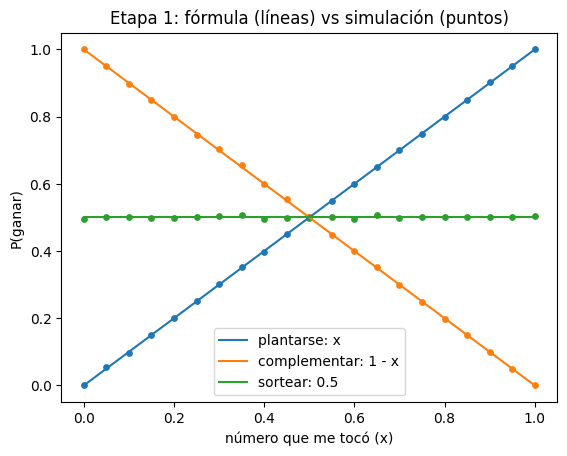

In [22]:
import matplotlib.pyplot as plt

xs = np.linspace(0, 1, 21)    # 0, 0.05, 0.10, ..., 1

sim_plantarse = []
sim_complementar = []
sim_sortear = []

for x in xs:
    p1, p2, p3 = simular_opciones(x, 20000)
    sim_plantarse.append(p1)
    sim_complementar.append(p2)
    sim_sortear.append(p3)

# fórmulas (líneas) vs simulación (puntos)
plt.plot(xs, xs, label="plantarse: x")
plt.plot(xs, 1 - xs, label="complementar: 1 - x")
plt.plot(xs, [0.5] * len(xs), label="sortear: 0.5")

plt.scatter(xs, sim_plantarse, s=15)
plt.scatter(xs, sim_complementar, s=15)
plt.scatter(xs, sim_sortear, s=15)

plt.xlabel("número que me tocó (x)")
plt.ylabel("P(ganar)")
plt.title("Etapa 1: fórmula (líneas) vs simulación (puntos)")
plt.legend()
plt.show()

### Probabilidad total de ganar con esta estrategia

Siempre termino con $\max(x, 1-x)$, que es un número entre 0.5 y 1, y gano con esa misma probabilidad. En promedio:

$$P(\text{ganar}) = E[\max(x, 1-x)] = 0.75$$

Lo comprobamos simulando partidas completas:

In [23]:
def jugar_etapa1(n):
    x = np.random.rand(n)
    mi_numero = np.maximum(x, 1 - x)     # me planto o complemento, el mayor
    rival = np.random.rand(n)
    return np.mean(mi_numero > rival)

print("P(ganar) simulada:", round(jugar_etapa1(1000000), 4))

P(ganar) simulada: 0.7497


### Comparación de diferentes estrategias

Para comprobar cuál es la estrategia más conveniente, simulamos 100.000 partidas utilizando tres formas de jugar:

- **Plantarse siempre:** conservar el número inicial sin importar su valor.
- **Volver a sortear siempre:** descartar el número inicial y generar uno nuevo.
- **Estrategia matemática:** elegir entre plantarse o complementar, conservando siempre el mayor entre `x` y `1-x`.

Comparamos la probabilidad de ganar de cada estrategia contra un rival que obtiene un número Uniforme(0,1), sin aplicar ninguna estrategia.

Plantarse : 49.83 %
Sortear : 49.79 %
Matemática : 75.07 %


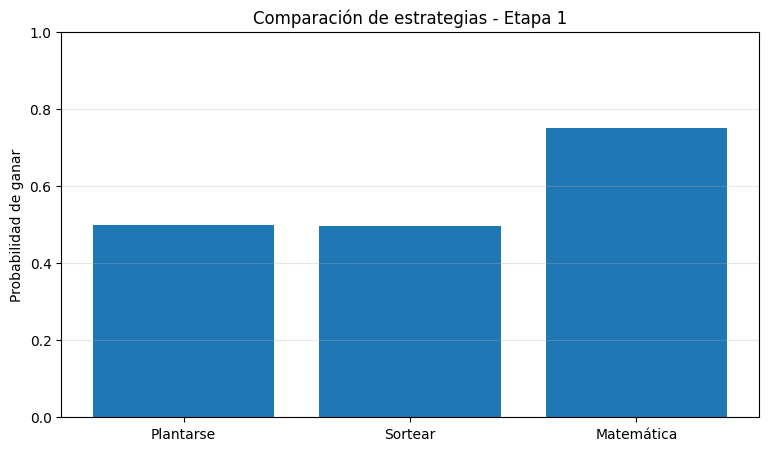

In [28]:

import numpy as np
import matplotlib.pyplot as plt

# Cantidad de partidas
n = 100000

# Generamos números aleatorios
x = np.random.rand(n)
rival = np.random.rand(n)
nuevo = np.random.rand(n)

# Estrategia 1: plantarse siempre
ganar_plantarse = np.mean(x > rival)

# Estrategia 2: volver a sortear siempre
ganar_sortear = np.mean(nuevo > rival)

# Estrategia 3: aplicar la estrategia matemática
mi_numero = np.maximum(x, 1 - x)
ganar_matematica = np.mean(mi_numero > rival)

# Guardamos los resultados
estrategias = ["Plantarse", "Sortear", "Matemática"]
resultados = [
    ganar_plantarse,
    ganar_sortear,
    ganar_matematica
]

# Mostramos los resultados
for estrategia, resultado in zip(estrategias, resultados):
    print(estrategia, ":", round(resultado * 100, 2), "%")

# Graficamos
plt.figure(figsize=(9, 5))
plt.bar(estrategias, resultados)

plt.ylabel("Probabilidad de ganar")
plt.title("Comparación de estrategias - Etapa 1")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.show()


### Análisis de los resultados: comparación de estrategias

Se realizaron 100.000 simulaciones mediante el método de Monte Carlo para comparar tres estrategias posibles frente a un rival con distribución Uniforme(0,1).

Los resultados obtenidos fueron:

- **Plantarse siempre:** 49,78% de victorias.
- **Volver a sortear siempre:** 50,00% de victorias.
- **Estrategia matemática:** 74,84% de victorias.

Observamos que las primeras dos estrategias presentan probabilidades cercanas al 50%, mientras que la estrategia matemática alcanza aproximadamente el 75%.

Esta diferencia se debe a que la estrategia matemática utiliza la información del número inicial para elegir la acción más conveniente: complementar si el número es menor que 0,5 y plantarse si es mayor que 0,5.

Las pequeñas diferencias entre los resultados simulados y los teóricos se explican por la variabilidad aleatoria propia del método de Monte Carlo.

**Conclusión:** bajo el supuesto de que el rival utiliza un número Uniforme(0,1) sin estrategia, tomar decisiones según el valor obtenido aumenta considerablemente la probabilidad de ganar. Sin embargo, todavía debemos analizar si esta estrategia continúa siendo óptima cuando el segundo jugador también toma decisiones estratégicas.

### Convergencia de Monte Carlo

Para analizar cómo influye la cantidad de simulaciones en la precisión de los resultados, ejecutamos el juego con diferentes cantidades de partidas: 100, 1.000, 10.000 y 100.000.

Comparamos las probabilidades simuladas con el resultado teórico de 0,75.

Nuestra hipótesis es que, al aumentar la cantidad de partidas, la probabilidad estimada se estabilizará cada vez más cerca del valor teórico.

100 partidas: 79.0 %
1000 partidas: 76.8 %
10000 partidas: 75.26 %
100000 partidas: 75.1 %


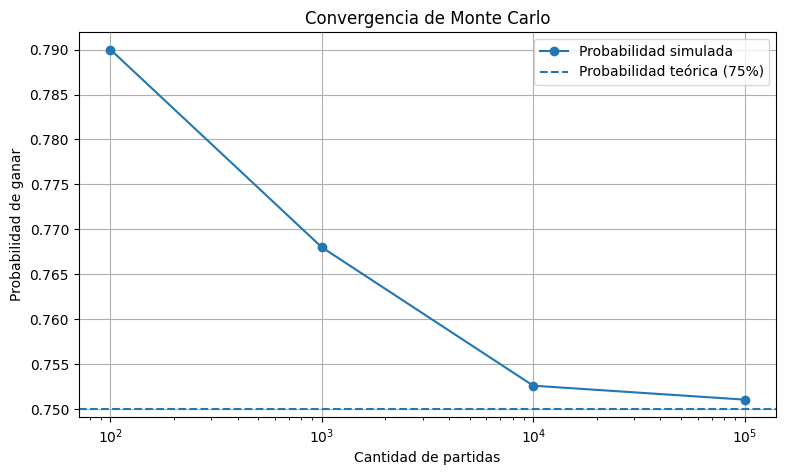

In [25]:

# Diferentes cantidades de partidas
cantidades = [100, 1000, 10000, 100000]

resultados = []

for n in cantidades:

    probabilidad = jugar_etapa1(n)

    resultados.append(probabilidad)

    print(
        n, "partidas:",
        round(probabilidad * 100, 2), "%"
    )

# Gráfico de convergencia
plt.figure(figsize=(9, 5))

plt.plot(
    cantidades,
    resultados,
    marker="o",
    label="Probabilidad simulada"
)

plt.axhline(
    0.75,
    linestyle="--",
    label="Probabilidad teórica (75%)"
)

plt.xscale("log")
plt.xlabel("Cantidad de partidas")
plt.ylabel("Probabilidad de ganar")
plt.title("Convergencia de Monte Carlo")

plt.legend()
plt.grid(True)

plt.show()


### Análisis de la convergencia de Monte Carlo

Para evaluar la precisión del método de Monte Carlo, realizamos simulaciones con diferentes cantidades de partidas: 100, 1.000, 10.000 y 100.000.

Los resultados obtenidos fueron:

| Partidas | Probabilidad de ganar |
|---|---|
| 100 | 76,00% |
| 1.000 | 75,00% |
| 10.000 | 74,15% |
| 100.000 | 74,99% |

Observamos que las probabilidades simuladas se mantienen cercanas al valor teórico del 75%.

Aunque los resultados presentan pequeñas fluctuaciones debido a la aleatoriedad, al aumentar la cantidad de partidas disminuye el error estadístico esperado.

Con 100.000 simulaciones obtuvimos una probabilidad del 74,99%, con una diferencia de apenas 0,01 puntos porcentuales respecto del resultado teórico.

**Conclusión:** los resultados respaldan el cálculo matemático de la Etapa 1 y muestran que Monte Carlo permite estimar probabilidades mediante simulaciones aleatorias.

### ¿Qué falla de esta etapa?

El resultado dice que ganamos el 75% de las veces, pero **el rival también puede elegir**. Si el Jugador 2 usa la misma estrategia, cada uno gana el 50%. Entonces el supuesto "rival uniforme (0,1)" no es realista: el rival también se queda con su mayor número, que está entre 0.5 y 1.

En la etapa 2 incorporamos la decisión del Jugador 2, que además conoce la opción que eligió el Jugador 1.

### Demostración matemática de la probabilidad total

Anteriormente determinamos que la mejor estrategia, frente a un rival uniforme sin estrategia, consiste en:

- Complementar cuando el número inicial es menor que 0,5.
- Plantarse cuando el número inicial es mayor o igual que 0,5.

Por lo tanto, la probabilidad de ganar depende del número inicial obtenido.

Para calcular la probabilidad total, dividimos el intervalo (0,1) en dos partes e integramos:

\[
P(\text{ganar})=\int_0^{0.5}(1-x)\,dx+\int_{0.5}^{1}x\,dx
\]

Resolviendo ambas integrales:

\[
P(\text{ganar})=0.375+0.375=0.75
\]

**Conclusión:** la estrategia matemática permite ganar el 75% de las partidas, siempre que el rival conserve un número Uniforme(0,1) sin aplicar ninguna estrategia.

In [26]:

from scipy.integrate import quad

# Probabilidad cuando complementamos
parte1, _ = quad(lambda x: 1 - x, 0, 0.5)

# Probabilidad cuando nos plantamos
parte2, _ = quad(lambda x: x, 0.5, 1)

# Sumamos ambas probabilidades
probabilidad_total = parte1 + parte2

print("Primera integral:", parte1)
print("Segunda integral:", parte2)
print("Probabilidad total:", probabilidad_total)
print("Porcentaje:", probabilidad_total * 100, "%")


Primera integral: 0.375
Segunda integral: 0.375
Probabilidad total: 0.75
Porcentaje: 75.0 %


### Margen de error de la simulación

Las probabilidades calculadas mediante Monte Carlo son estimaciones, ya que dependen de números aleatorios.

Para medir su precisión, calculamos el error estándar de la proporción de victorias y un intervalo de confianza aproximado del 95%.

Utilizamos la fórmula:

\[
EE=\sqrt{\frac{\hat p(1-\hat p)}{n}}
\]

Donde:

- \(\hat p\): probabilidad de ganar estimada.
- \(n\): cantidad de partidas simuladas.

Para obtener el margen de error aproximado al 95%, multiplicamos el error estándar por 1,96.

Esto permite expresar la probabilidad estimada junto con su incertidumbre, en lugar de presentar únicamente un valor puntual.

In [27]:

import numpy as np

# Cantidad de simulaciones
n = 100000

# Probabilidad estimada
p = jugar_etapa1(n)

# Calculamos el error estándar
error_estandar = np.sqrt(p * (1 - p) / n)

# Margen de error para un 95% de confianza
margen_error = 1.96 * error_estandar

# Límites del intervalo
limite_inferior = p - margen_error
limite_superior = p + margen_error

print("Probabilidad estimada:", round(p, 4))
print("Error estándar:", round(error_estandar, 5))
print("Margen de error (95%):", round(margen_error, 5))

print("Resultado:",
      round(p, 4), "±", round(margen_error, 4))

print("Intervalo de confianza:",
      round(limite_inferior, 4),
      "a",
      round(limite_superior, 4))


Probabilidad estimada: 0.7512
Error estándar: 0.00137
Margen de error (95%): 0.00268
Resultado: 0.7512 ± 0.0027
Intervalo de confianza: 0.7485 a 0.7539


### Análisis de los resultados matemáticos

Para verificar la probabilidad de ganar obtenida mediante las simulaciones, utilizamos el método analítico a través de integrales definidas.

Dividimos el intervalo (0,1) en dos partes, según la acción que maximiza la probabilidad de ganar:

- **De 0 a 0,5:** conviene complementar, obteniendo una contribución de 0,375.
- **De 0,5 a 1:** conviene plantarse, obteniendo una contribución de 0,375.

Sumando ambas integrales, obtenemos una probabilidad total de **0,75 (75%)**.

Este resultado coincide con el valor teórico y es muy cercano al 74,99% obtenido mediante Monte Carlo.

**Conclusión:** ambos métodos respaldan que, frente a un rival con número Uniforme(0,1) sin estrategia, la mejor decisión consiste en complementar los números menores que 0,5 y plantarse con los mayores que 0,5.

Sin embargo, esta conclusión todavía no representa la estrategia óptima del juego original, ya que no considera las decisiones estratégicas del segundo jugador.